# Pakistan's Middle and Affluent Class (MAC): the 2024-25 update

This notebook recreates the four panels of the infographic **"Pakistan's Booming Middle and Affluent Class"** (KSBL Initiative on the Digital Economy, Dr. Jawaid Abdul Ghani, 25 July 2018; file `reference/2018 KIDE MAC.pdf`). It adds **2024-25** as a new year, computed from the HIES 2024-25 microdata with the survey weights.

The infographic's definitions, which we copy exactly:

| Class | Spending per person per **day**, in 2011 PPP dollars |
|---|---|
| Poor | under $2 |
| LC (lower class) | $2 – 4 |
| LMC (lower middle class) | $4 – 6 |
| MAC (middle and affluent class) | over $6 |

These are **fixed** lines. That is why they can be compared across years, unlike the K-means classes in the other notebook, which move every year.

**Needs:** run `../1_social_classes/social_classes_kmeans_knn.ipynb` first. It creates `../1_social_classes/outputs/household_classes.csv` with every household's monthly spending and weight.


## Step 1: Turn "2011 dollars" into 2024-25 rupees

Two numbers are needed:

1. **PPP rate for 2011:** how many rupees bought what one international dollar bought in 2011 (household consumption). Source: World Bank, *PPP conversion factor, private consumption* (`PA.NUS.PRVT.PP`), via Our World in Data.
2. **Price rise from 2011 to 2024-25:** World Bank consumer price index (`FP.CPI.TOTL`, 2010 = 100), via Our World in Data. Fieldwork ran from October 2024 to June 2025, so we average the 2024 and 2025 index values.

> **Caveat.** The World Bank now publishes PPPs based on the 2021 price survey (ICP 2021), so its value for 2011 is not exactly the number the 2018 infographic used, which came from ICP 2011. Step 6 shows how much the results move if the rate is 10% higher or lower.

### Also shown in 2025 dollars

A 2025 dollar buys less than a 2011 dollar. So we also show every line and amount in **2025 international dollars**, using the World Bank PPP rate for 2024-25 (average of 2024 and 2025, about Rs 65 per $). The **class lines stay exactly the same in rupees**, so nobody changes class; only the dollar labels change. For example, "$6 a day in 2011 dollars" = "$8.26 a day in 2025 dollars" = the same Rs 538 a day.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "../../HIES 2024_2025/Stata data/"
EXP1 = "../1_social_classes/outputs/"  # made by Experiment 1
OUT = "outputs/"

PPP_2011 = 25.495556                       # Rs per international $ (private consumption), 2011
CPI_2011 = 111.91609                       # CPI, 2010 = 100
CPI_2024_25 = (386.80386 + 400.5182) / 2   # average of 2024 and 2025
RS_PER_USD = PPP_2011 * CPI_2024_25 / CPI_2011
PPP_2024_25 = (64.86099 + 65.39615) / 2    # Rs per international $ (private consumption), average of 2024 and 2025
TO_2025_USD = RS_PER_USD / PPP_2024_25     # one 2011 dollar expressed in 2025 dollars
DAYS_PER_MONTH = 365 / 12

print(f"Prices rose {CPI_2024_25 / CPI_2011:.2f} times from 2011 to 2024-25")
print(f"1 dollar (2011 PPP) = Rs {RS_PER_USD:,.2f} in 2024-25 prices")
print(f"1 dollar (2025 PPP) = Rs {PPP_2024_25:,.2f}   ->   $1 in 2011 dollars = ${TO_2025_USD:.2f} in 2025 dollars\n")
print("Class lines, spending per person:")
for usd in (2, 4, 6):
    print(f"  ${usd}/day (2011 $) = ${usd * TO_2025_USD:.2f}/day (2025 $) = Rs {usd * RS_PER_USD:,.0f} per day "
          f"= Rs {usd * RS_PER_USD * DAYS_PER_MONTH:,.0f} per month")


Prices rose 3.52 times from 2011 to 2024-25
1 dollar (2011 PPP) = Rs 89.68 in 2024-25 prices
1 dollar (2025 PPP) = Rs 65.13   ->   $1 in 2011 dollars = $1.38 in 2025 dollars

Class lines, spending per person:
  $2/day (2011 $) = $2.75/day (2025 $) = Rs 179 per day = Rs 5,456 per month
  $4/day (2011 $) = $5.51/day (2025 $) = Rs 359 per day = Rs 10,911 per month
  $6/day (2011 $) = $8.26/day (2025 $) = Rs 538 per day = Rs 16,367 per month


## Step 2: Put every household in a class

Spending per person comes from Section 6A, built in the other notebook: all items, all sources, converted to a monthly amount. Population counts use **weight × household size**, so they describe Pakistan's population, not the sample.


In [2]:
CLASSES = ["Poor", "LC", "LMC", "MAC"]
hh = pd.read_csv(EXP1 + "household_classes.csv")
hh["usd_per_day"] = hh.per_person / DAYS_PER_MONTH / RS_PER_USD

def assign(usd):
    return pd.cut(usd, [-np.inf, 2, 4, 6, np.inf], labels=CLASSES, right=False)

hh["mac_class"] = assign(hh.usd_per_day)
g = hh.groupby("mac_class", observed=True)
size = pd.DataFrame({
    "people (million)": g.people_w.sum() / 1e6,
    "% of people": g.people_w.sum() / hh.people_w.sum() * 100,
    "% of households": g.weight.sum() / hh.weight.sum() * 100,
    "consumption ($ billion, 2011 PPP, per year)":
        g.apply(lambda d: (d.weight * d.monthly_total).sum() * 12 / RS_PER_USD / 1e9, include_groups=False),
}).reindex(CLASSES)
size["consumption ($ billion, 2025 PPP, per year)"] = size["consumption ($ billion, 2011 PPP, per year)"] * TO_2025_USD
print(f"Total population covered: {hh.people_w.sum() / 1e6:,.1f} million")
size.round(1)


Total population covered: 239.8 million


,people (million),% of people,% of households,"consumption ($ billion, 2011 PPP, per year)","consumption ($ billion, 2025 PPP, per year)"
mac_class,,,,,
Poor,22.3,9.3,7.0,13.4,18.5
LC,106.2,44.3,39.4,115.2,158.6
LMC,58.1,24.2,25.5,102.8,141.6
MAC,53.2,22.2,28.1,205.3,282.6


## Step 3: Durable goods (Section 7)

A household "owns" an item if it owns at least one **now** (`s7m_b` > 0):

- motorbike = motorcycle or scooter (codes 728, 729)
- fridge (704)
- washing machine (706)
- TV = television or LCD/LED (702, 703)


In [3]:
s7 = pd.read_stata(DATA + "sec_7.dta", convert_categoricals=False)
s7["hhcode"] = s7.hhcode.round().astype("int64")
owned_now = s7[s7.s7m_b.fillna(0) > 0]
ITEMS = {"Motorbike": [728, 729], "Fridge": [704], "Washing machine": [706], "TV": [702, 703]}

durables = {}
for item, codes in ITEMS.items():
    has = hh.hhcode.isin(set(owned_now[owned_now.itc.isin(codes)].hhcode))
    row = {"All households": (hh.weight * has).sum() / hh.weight.sum() * 100}
    for c in CLASSES:
        m = hh.mac_class == c
        row[c] = (hh.weight[m] * has[m]).sum() / hh.weight[m].sum() * 100
    durables[item] = row
durables = pd.DataFrame(durables).T
print("% of households owning each item, 2024-25 (weighted)")
durables.round(0)


% of households owning each item, 2024-25 (weighted)


,All households,Poor,LC,LMC,MAC
Motorbike,57.0,29.0,48.0,61.0,72.0
Fridge,56.0,13.0,39.0,64.0,82.0
Washing machine,61.0,18.0,47.0,70.0,85.0
TV,52.0,17.0,37.0,58.0,77.0


## Step 4: % of households in MAC, by city

HIES 2024-25 codes urban areas by **division**: the first 3 digits of `prcode` are the division and the 4th digit is 2 for urban (see `Coding-Scheme-HIES-2024-25-RUralUrban.xlsx`). A "city" here means **the urban part of its division**. For Karachi that is essentially the city; for Lahore or Faisalabad it also includes nearby towns. "Isl-Pindi" combines Islamabad (610) and Rawalpindi Division (210), as in the infographic.


In [4]:
CITY = {"Isl-Pindi": ["610", "210"], "Peshawar": ["140"], "Quetta": ["410"], "Gujranwala": ["240"],
        "Lahore": ["250"], "Hyderabad": ["330"], "Karachi": ["350"], "Multan": ["270"], "Faisalabad": ["230"]}
code_str = hh.prcode.astype(str)
urban_div = code_str.str[:3].where(code_str.str[3] == "2")

city = {}
for name, codes in CITY.items():
    d = hh[urban_div.isin(codes)]
    city[name] = {"sample households": len(d),
                  "% of households in MAC": (d.weight * (d.mac_class == "MAC")).sum() / d.weight.sum() * 100}
city = pd.DataFrame(city).T.sort_values("% of households in MAC", ascending=False)
city.round(1)


,sample households,% of households in MAC
Isl-Pindi,590.0,52.0
Karachi,1964.0,50.0
Lahore,1374.0,48.1
Faisalabad,542.0,42.1
Gujranwala,627.0,40.8
Peshawar,854.0,37.6
Hyderabad,499.0,34.4
Quetta,522.0,28.6
Multan,429.0,22.1


## Step 5: Put 2024-25 next to the infographic's years

The 1990-91, 2001-02 and 2014-16 numbers are typed in **exactly as printed** in the 2018 infographic. We do not have the microdata for those years yet, so we cannot check them or make sure they were built the same way. Treat 2024-25 vs earlier years as **indicative, not exact**: the spending list, the PPP vintage and other details may differ.


In [5]:
# As printed in "2018 KIDE MAC.pdf"
published_pop = pd.DataFrame({"1990-91": [59, 39, 7, 4], "2001-02": [79, 48, 9, 5], "2015-16": [21, 84, 49, 45]}, index=CLASSES)
published_cons = pd.DataFrame({"1990-91": [28, 38, 12, 15], "2001-02": [35, 43, 14, 14], "2015-16": [13, 92, 88, 169]}, index=CLASSES)
published_dur = pd.DataFrame({"1990-91": [4, 10, 13, 22], "2001-02": [7, 16, 25, 30], "2014-15": [41, 47, 48, 62]}, index=list(ITEMS))
published_city = pd.Series({"Isl-Pindi": 62, "Peshawar": 52, "Quetta": 50, "Gujranwala": 44, "Lahore": 42,
                            "Hyderabad": 39, "Karachi": 39, "Multan": 33, "Faisalabad": 25}, name="2015-16")

YEAR = "2024-25"
pop = published_pop.assign(**{YEAR: size["people (million)"].round(0).to_numpy()})
cons = published_cons.assign(**{YEAR: size["consumption ($ billion, 2011 PPP, per year)"].round(0).to_numpy()})
dur = published_dur.assign(**{YEAR: durables["All households"].round(0).to_numpy()})
cities = pd.DataFrame({"2015-16": published_city, YEAR: city["% of households in MAC"].round(0)})
cities = cities.sort_values(YEAR)

for title, t in [("Population (million)", pop), ("Consumption ($ billion, 2011 PPP)", cons),
                 ("Durable ownership (% of households)", dur), ("% of households in MAC, by city", cities)]:
    print(title); display(t.astype(int)); print()


Population (million)


,1990-91,2001-02,2015-16,2024-25
Poor,59,79,21,22
LC,39,48,84,106
LMC,7,9,49,58
MAC,4,5,45,53



Consumption ($ billion, 2011 PPP)


,1990-91,2001-02,2015-16,2024-25
Poor,28,35,13,13
LC,38,43,92,115
LMC,12,14,88,103
MAC,15,14,169,205



Durable ownership (% of households)


,1990-91,2001-02,2014-15,2024-25
Motorbike,4,7,41,57
Fridge,10,16,47,56
Washing machine,13,25,48,61
TV,22,30,62,52



% of households in MAC, by city


,2015-16,2024-25
Multan,33,22
Quetta,50,29
Hyderabad,39,34
Peshawar,52,38
Gujranwala,44,41
Faisalabad,25,42
Lahore,42,48
Karachi,39,50
Isl-Pindi,62,52


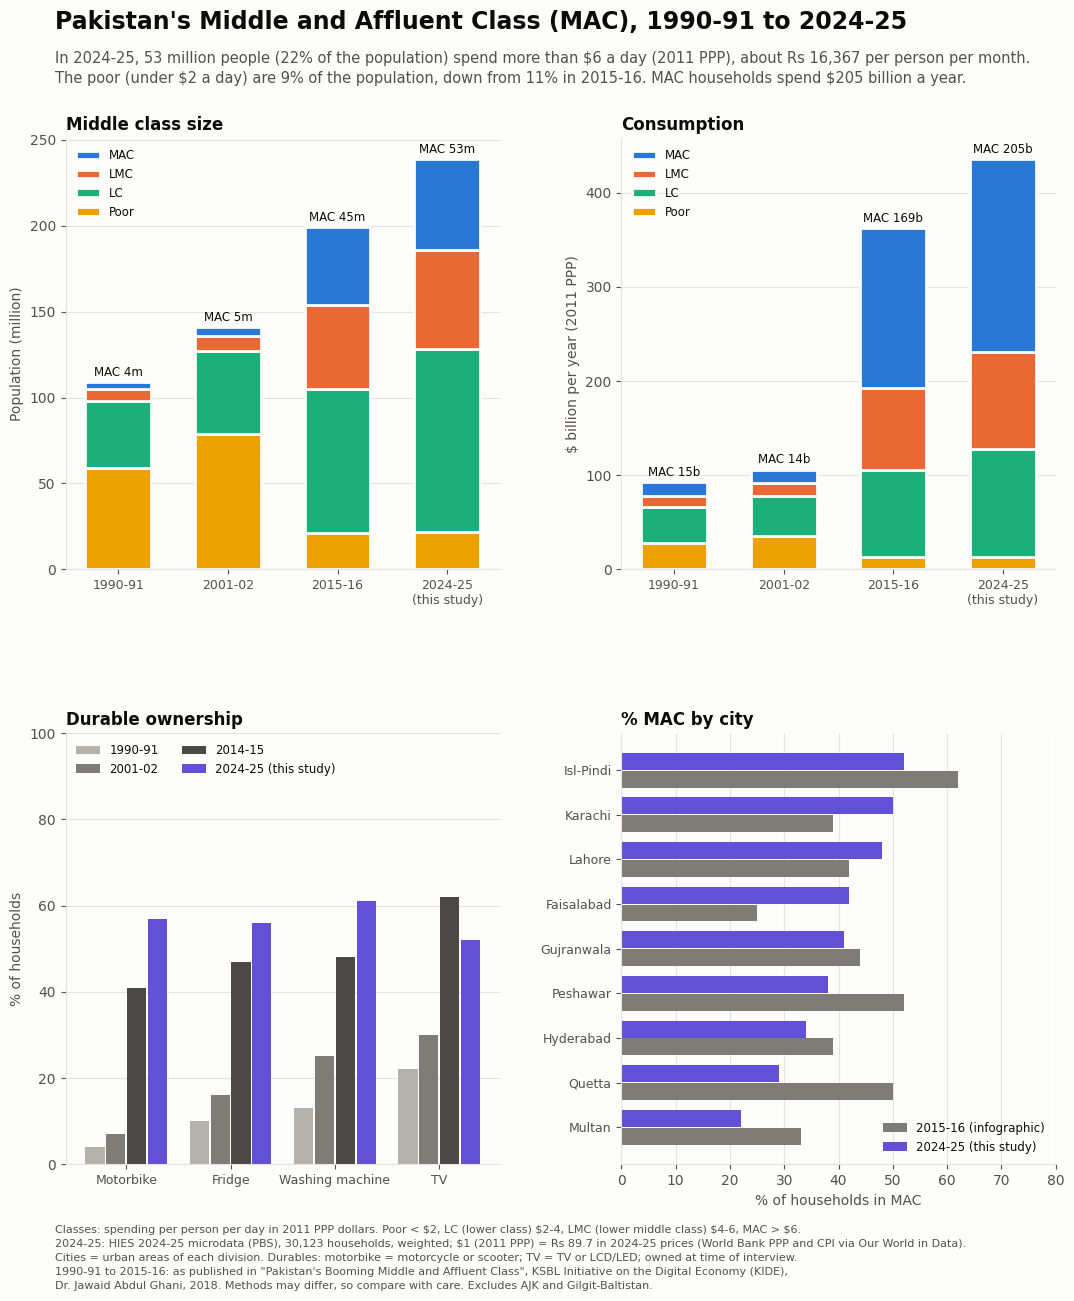

In [6]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CLASS_COLOURS = ["#eda100", "#1baf7a", "#eb6834", "#2a78d6"]   # Poor yellow, LC green, LMC orange, MAC blue (high contrast)
YEAR_COLOURS = ["#b4b3ab", "#7d7c76", "#4a4945", "#6250d6"]    # older years in greys, 2024-25 in violet so it stands out
OLD_YEAR, NEW_YEAR = "#7d7c76", "#6250d6"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "text.parse_math": False})   # so "$" is shown as a dollar sign

def grid(ax, axis="y"):
    ax.grid(axis=axis, color=GRID, lw=0.8); ax.set_axisbelow(True)

def year_labels(cols):
    return [f"{c}\n(this study)" if c == YEAR else c for c in cols]

def stacked(ax, table, title, ylabel, unit):
    x = np.arange(table.shape[1]); bottom = np.zeros(table.shape[1])
    for cls, colour in zip(CLASSES, CLASS_COLOURS):
        v = table.loc[cls].to_numpy(dtype=float)
        ax.bar(x, v, 0.6, bottom=bottom, color=colour, label=cls, edgecolor=SURFACE, linewidth=2)
        bottom += v
    for xi, total, mac in zip(x, bottom, table.loc["MAC"]):
        ax.text(xi, total + bottom.max() * 0.015, f"MAC {mac:.0f}{unit}", ha="center", fontsize=8.5, color=INK)
    ax.set_xticks(x, year_labels(table.columns), fontsize=9)
    ax.set_ylabel(ylabel); ax.set_title(title, loc="left", fontsize=12, fontweight="bold"); grid(ax)
    ax.legend(title=None, frameon=False, fontsize=8.5, loc="upper left", reverse=True)

mac_now = size.loc["MAC"]
fig = plt.figure(figsize=(11, 13.5))
fig.text(0.06, 0.975, "Pakistan's Middle and Affluent Class (MAC), 1990-91 to 2024-25", fontsize=17, fontweight="bold", va="top")
fig.text(0.06, 0.945,
         f"In 2024-25, {mac_now['people (million)']:.0f} million people ({mac_now['% of people']:.0f}% of the population) spend more than $6 a day "
         f"(2011 PPP), about Rs {6 * RS_PER_USD * DAYS_PER_MONTH:,.0f} per person per month.\n"
         f"The poor (under $2 a day) are {size.loc['Poor', '% of people']:.0f}% of the population, down from 11% in 2015-16. "
         f"MAC households spend ${mac_now['consumption ($ billion, 2011 PPP, per year)']:.0f} billion a year.",
         fontsize=10.5, va="top", color=INK_2, linespacing=1.5)

gs = fig.add_gridspec(2, 2, left=0.07, right=0.97, top=0.88, bottom=0.12, hspace=0.38, wspace=0.28)
stacked(fig.add_subplot(gs[0, 0]), pop, "Middle class size", "Population (million)", "m")
stacked(fig.add_subplot(gs[0, 1]), cons, "Consumption", "$ billion per year (2011 PPP)", "b")

ax = fig.add_subplot(gs[1, 0])
x = np.arange(len(ITEMS)); n = dur.shape[1]; bw = 0.8 / n
for i, (yr, colour) in enumerate(zip(dur.columns, YEAR_COLOURS)):
    ax.bar(x - 0.4 + bw * (i + 0.5), dur[yr], bw * 0.92, color=colour, label=year_labels([yr])[0].replace("\n", " "))
ax.set_xticks(x, list(ITEMS), fontsize=9)
ax.set_ylabel("% of households"); ax.set_ylim(0, 100)
ax.set_title("Durable ownership", loc="left", fontsize=12, fontweight="bold"); grid(ax)
ax.legend(frameon=False, fontsize=8.5, loc="upper left", ncol=2)

ax = fig.add_subplot(gs[1, 1])
y = np.arange(len(cities)); bh = 0.38
ax.barh(y - bh / 2 - 0.01, cities["2015-16"], bh, color=OLD_YEAR, label="2015-16 (infographic)")
ax.barh(y + bh / 2 + 0.01, cities[YEAR], bh, color=NEW_YEAR, label=f"{YEAR} (this study)")
ax.set_yticks(y, cities.index, fontsize=9)
ax.set_xlabel("% of households in MAC"); ax.set_xlim(0, 80)
ax.set_title("% MAC by city", loc="left", fontsize=12, fontweight="bold"); grid(ax, "x")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")

fig.text(0.06, 0.075,
         "Classes: spending per person per day in 2011 PPP dollars. Poor < $2, LC (lower class) $2-4, LMC (lower middle class) $4-6, MAC > $6.\n"
         f"2024-25: HIES 2024-25 microdata (PBS), 30,123 households, weighted; $1 (2011 PPP) = Rs {RS_PER_USD:.1f} in 2024-25 prices "
         "(World Bank PPP and CPI via Our World in Data).\n"
         "Cities = urban areas of each division. Durables: motorbike = motorcycle or scooter; TV = TV or LCD/LED; owned at time of interview.\n"
         "1990-91 to 2015-16: as published in \"Pakistan's Booming Middle and Affluent Class\", KSBL Initiative on the Digital Economy (KIDE),\n"
         "Dr. Jawaid Abdul Ghani, 2018. Methods may differ, so compare with care. Excludes AJK and Gilgit-Baltistan.",
         fontsize=8, color=INK_2, va="top", linespacing=1.5)

plt.savefig(OUT + "mac_infographic_2024_25.png", dpi=150)
plt.savefig(OUT + "mac_infographic_2024_25.pdf")
plt.show()


## Step 6: How sure are we? Changing the dollar conversion

The rupee value of "$1 in 2011" is the biggest assumption. Here we move it 10% up and down and see how the class sizes change.


In [7]:
rows = {}
for label, factor in [("rate 10% lower", 0.9), ("our rate", 1.0), ("rate 10% higher", 1.1)]:
    usd = hh.per_person / DAYS_PER_MONTH / (RS_PER_USD * factor)
    cls = assign(usd)
    rows[f"{label} (Rs {RS_PER_USD * factor:.0f} per $)"] = (hh.people_w.groupby(cls, observed=True).sum() / hh.people_w.sum() * 100).reindex(CLASSES)
print("% of people in each class")
pd.DataFrame(rows).T.round(1)


% of people in each class


per_person,Poor,LC,LMC,MAC
rate 10% lower (Rs 81 per $),5.9,40.1,26.7,27.2
our rate (Rs 90 per $),9.3,44.3,24.2,22.2
rate 10% higher (Rs 99 per $),13.3,47.0,21.5,18.2


### Step 6b: The same results in 2025 dollars, and a trap to avoid

**Option A (used in the report):** keep the class lines in rupees and just restate them in 2025 dollars. Class sizes do not change, and dollar amounts get bigger because a 2025 dollar is worth less.

**Option B (not used):** treat "$2 / $4 / $6" as **2025** dollars. That **lowers** the lines in rupees, so many people "move up" only because the bar got lower, not because they got richer. This breaks the comparison with 1990-2015. It is shown below only so you can see why.


In [8]:
lines = pd.DataFrame({
    "2011 $ per day": ["under 2", "2 - 4", "4 - 6", "over 6"],
    "2025 $ per day": [f"under {2 * TO_2025_USD:.2f}", f"{2 * TO_2025_USD:.2f} - {4 * TO_2025_USD:.2f}",
                       f"{4 * TO_2025_USD:.2f} - {6 * TO_2025_USD:.2f}", f"over {6 * TO_2025_USD:.2f}"],
    "Rs per person per month": [f"under {2 * RS_PER_USD * DAYS_PER_MONTH:,.0f}",
                                f"{2 * RS_PER_USD * DAYS_PER_MONTH:,.0f} - {4 * RS_PER_USD * DAYS_PER_MONTH:,.0f}",
                                f"{4 * RS_PER_USD * DAYS_PER_MONTH:,.0f} - {6 * RS_PER_USD * DAYS_PER_MONTH:,.0f}",
                                f"over {6 * RS_PER_USD * DAYS_PER_MONTH:,.0f}"],
}, index=CLASSES)
display(lines)
display(size[["% of people", "consumption ($ billion, 2011 PPP, per year)", "consumption ($ billion, 2025 PPP, per year)"]].round(0))

option_b = assign(hh.per_person / DAYS_PER_MONTH / PPP_2024_25)
compare = pd.DataFrame({
    "Option A: same lines (report)": size["% of people"],
    "Option B: $2/$4/$6 as 2025 dollars": hh.people_w.groupby(option_b, observed=True).sum().reindex(CLASSES) / hh.people_w.sum() * 100,
})
print("% of people in each class")
compare.round(1)


,2011 $ per day,2025 $ per day,Rs per person per month
Poor,under 2,under 2.75,"under 5,456"
LC,2 - 4,2.75 - 5.51,"5,456 - 10,911"
LMC,4 - 6,5.51 - 8.26,"10,911 - 16,367"
MAC,over 6,over 8.26,"over 16,367"


,% of people,"consumption ($ billion, 2011 PPP, per year)","consumption ($ billion, 2025 PPP, per year)"
mac_class,,,
Poor,9.0,13.0,18.0
LC,44.0,115.0,159.0
LMC,24.0,103.0,142.0
MAC,22.0,205.0,283.0


% of people in each class


,Option A: same lines (report),Option B: $2/$4/$6 as 2025 dollars
Poor,9.3,2.1
LC,44.3,28.1
LMC,24.2,29.5
MAC,22.2,40.3


## What it shows (2024-25 vs. the infographic's 2015-16)

Read the comparison as **indicative**: the earlier years come from a different study, and we can't re-check them until we have that microdata.

- **MAC:** 53 million people (22%) in 2024-25 vs 45 million (23%) in 2015-16. The MAC kept growing in numbers along with the population, but its share of the population has stayed about flat. **Careful:** this depends on the dollar conversion. If $1 (2011 PPP) is worth 10% fewer or more rupees, the 2024-25 MAC share becomes 27% or 18% (Step 6). So "about flat" means "somewhere between a small fall and a small rise".
- **Poverty fell further:** about 22 million people (9%) spend under $2 a day, vs 21 million (11%) in 2015-16. The share dropped while the population grew.
- **The lower class (LC) is now the biggest group** (44%). Many people moved up out of poverty but not yet into the middle.
- **MAC households spend about $205 billion a year** (2011 PPP), the largest share of all consumption.
- **Durables:** motorbike ownership rose from 41% to about 57% of households, and fridges and washing machines rose too. **TV ownership fell** (62% to about 52%), likely because people now watch on smartphones.
- **Cities:** Islamabad-Pindi, Karachi and Lahore have the highest MAC shares (about 48-52%). Quetta, Peshawar and Multan are lower than the infographic reported for 2015-16. Those are the cities where our "urban division" areas are much wider than the city itself, so part of that drop may come from the definition.

**Next step:** download the older microdata rounds, run the same code on each, and replace the published numbers with our own. Then every year uses exactly the same method.


## Step 7: Build the 2-page report PDF

- **Page 1** follows the layout of the 2018 KIDE infographic: headline, definitions, two charts with data tables, findings text, two more charts, sources.
- **Page 2** adds what is behind the numbers: key figures, what the class lines mean in rupees, classes by province and rural/urban, what each class owns, and the methods and cautions.

All wording is filled in from the numbers above, so it updates automatically if the data changes.


In [9]:
import textwrap
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import FancyBboxPatch

A4 = (8.27, 11.69)
PREPARED_BY = "Prepared by Khalid Siddiqi, GUTECH PSLM Project"
DATE = "November 2026"
SHARE_2015 = {"Poor": 11, "LC": 42, "LMC": 25, "MAC": 23}   # % of population, 2015-16 (infographic text)
pct = size["% of people"].round(0).astype(int)
ppl = size["people (million)"].round(0).astype(int)
usd = size["consumption ($ billion, 2011 PPP, per year)"].round(0).astype(int)
usd25 = size["consumption ($ billion, 2025 PPP, per year)"].round(0).astype(int)
line_month = {d: d * RS_PER_USD * DAYS_PER_MONTH for d in (2, 4, 6)}

def wrap(text, width):
    return "\n".join(textwrap.fill(p, width) for p in text.split("\n"))

def para(fig, y, text, width, size=9, style="normal", weight="normal", color=INK, x=0.07, ha="left"):
    fig.text(x, y, wrap(text, width), fontsize=size, style=style, weight=weight, color=color, va="top", ha=ha, linespacing=1.45)

from matplotlib.colors import to_rgb

def readable_text_on(colour):
    # white text on dark swatches, black text on light ones
    r, g, b = [v / 12.92 if v <= 0.03928 else ((v + 0.055) / 1.055) ** 2.4 for v in to_rgb(colour)]
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.2 else INK

def style_table(t, swatch_rows_white=None):
    t.auto_set_font_size(False); t.set_fontsize(7.5)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor(GRID); cell.set_linewidth(0.6)
        if r == 0: cell.set_text_props(weight="bold", color=INK_2)
        if c == -1 and r > 0: cell.get_text().set_color(readable_text_on(cell.get_facecolor())); cell.get_text().set_weight("bold")

def stacked_with_table(ax, table, title, ylabel, fmt):
    years = list(table.columns); x = np.arange(len(years)); bottom = np.zeros(len(years))
    for cls, colour in zip(CLASSES, CLASS_COLOURS):
        v = table.loc[cls].to_numpy(dtype=float)
        ax.bar(x, v, 0.55, bottom=bottom, color=colour, edgecolor=SURFACE, linewidth=1.5)
        bottom += v
    ax.set_xlim(-0.5, len(years) - 0.5); ax.set_xticks([])
    ax.set_ylabel(ylabel, fontsize=8); ax.tick_params(labelsize=7.5); grid(ax)
    ax.set_title(title, fontsize=11.5, weight="bold", loc="left")
    rows = list(reversed(CLASSES))
    t = ax.table(cellText=[[fmt(v) for v in table.loc[c]] for c in rows], rowLabels=rows,
                 colLabels=[f"{y}*" if y == YEAR else y for y in years], rowColours=list(reversed(CLASS_COLOURS)),
                 cellLoc="center", bbox=[0, -0.6, 1, 0.52])
    style_table(t, swatch_rows_white={1, 2, 3})

def tile(fig, x, y, w, h, value, label):
    fig.patches.append(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.004,rounding_size=0.008",
                                      transform=fig.transFigure, facecolor="#f0f6fe", edgecolor="#cde2fb", lw=1))
    fig.text(x + 0.015, y + h - 0.012, value, fontsize=15, weight="bold", color=INK, va="top")
    fig.text(x + 0.015, y + 0.012, wrap(label, 28), fontsize=7.8, color=INK_2, va="bottom", linespacing=1.3)

def footer(fig, page):
    fig.add_artist(plt.Line2D([0.07, 0.93], [0.045, 0.045], color=GRID, lw=0.8, transform=fig.transFigure))
    fig.text(0.07, 0.035, "Data source: Household Integrated Economic Survey (HIES) 2024-25, Pakistan Bureau of Statistics; "
             "1990-91 to 2015-16 from KIDE (2018).", fontsize=6.8, color=INK_2, va="top")
    fig.text(0.07, 0.02, PREPARED_BY, fontsize=7.5, weight="bold", va="top")
    fig.text(0.93, 0.02, f"{DATE}  ·  page {page}", fontsize=7.5, weight="bold", va="top", ha="right")

# ---------------- wording ----------------
headline = (f"Between 2015-16 and 2024-25 the Middle & Affluent Class (MAC) grew from 45 to {ppl['MAC']} million people, "
            f"and MAC annual consumption increased from $169 billion to ${usd['MAC']}b (${usd25['MAC']}b in 2025 dollars). "
            f"The lower middle class (LMC) grew "
            f"from 49m to {ppl['LMC']}m and its consumption from $88b to ${usd['LMC']}b, while the share of people living "
            f"in poverty fell from 11% to {pct['Poor']}%.")
note = (f"Note: $ amounts are in 2011 purchasing power parity (PPP) dollars; $1 (2011) = "
        f"Rs {RS_PER_USD:.1f} at 2024-25 prices = ${TO_2025_USD:.2f} in 2025 PPP dollars. "
        f"Classes are based on daily spending per person: MAC over $6 (= ${6 * TO_2025_USD:.2f} in 2025 dollars, "
        f"about Rs {line_month[6]:,.0f} per person per month), "
        f"LMC $4-6, LC (lower class) $2-4, and poor under $2 (Rs {line_month[2]:,.0f} a month). "
        f"Between 2015-16 and 2024-25 the share of the population classified as MAC went from 23% to {pct['MAC']}%, "
        f"LMC from 25% to {pct['LMC']}%, LC from 42% to {pct['LC']}%, and poor from 11% to {pct['Poor']}%. "
        f"* 2024-25 is calculated from HIES microdata; earlier years are as published by KIDE (2018), so methods may differ.")
d_now, d_mac = durables["All households"].round(0).astype(int), durables["MAC"].round(0).astype(int)
city_sorted = city["% of households in MAC"].sort_values(ascending=False).round(0).astype(int)
city_list = ", ".join(f"{c} {v}%" for c, v in city_sorted.iloc[1:-1].items())
middle_text = (f"Between 2014-15 and 2024-25 the share of households owning a motorbike rose from 41% to {d_now['Motorbike']}%, "
               f"a fridge from 47% to {d_now['Fridge']}% and a washing machine from 48% to {d_now['Washing machine']}%, "
               f"while TV ownership fell from 62% to {d_now['TV']}%. Most MAC households now own a fridge ({d_mac['Fridge']}%) "
               f"and a washing machine ({d_mac['Washing machine']}%).\n"
               f"{city_sorted.iloc[0]}% of {city_sorted.index[0]} households belong to MAC; {city_list}; "
               f"and {city_sorted.index[-1]} {city_sorted.iloc[-1]}%.")

# ---------------- page 2 data ----------------
area = hh.province.map({"kp": "KP", "punjab": "Punjab", "sindh": "Sindh", "balochistan": "Balochistan"})
area = area.where(hh.prcode.astype(str).str[0] != "6", "Islamabad")
groups = {"Pakistan": pd.Series(True, index=hh.index), "Urban": hh.region == "urban", "Rural": hh.region == "rural",
          **{a: area == a for a in ["Islamabad", "Punjab", "Sindh", "KP", "Balochistan"]}}
by_area = pd.DataFrame({g: hh[m].groupby("mac_class", observed=True).people_w.sum().reindex(CLASSES) / hh[m].people_w.sum() * 100
                        for g, m in groups.items()}).T
hh_size = hh.groupby("mac_class", observed=True).apply(lambda d: np.average(d.hhsize, weights=d.weight), include_groups=False).reindex(CLASSES)

with PdfPages(OUT + "MAC_report_2024_25.pdf") as pdf:
    # ================= PAGE 1 =================
    fig = plt.figure(figsize=A4)
    fig.text(0.5, 0.968, "Pakistan's Middle and Affluent Class (MAC), 1990-91 to 2024-25", ha="center", fontsize=14.5, weight="bold")
    para(fig, 0.945, headline, 92, size=10, style="italic", weight="bold")
    para(fig, 0.872, note, 128, size=7.6, color=INK_2)

    stacked_with_table(fig.add_axes([0.14, 0.575, 0.33, 0.19]), pop, "Middle class size", "Population (million)", lambda v: f"{v:.0f}")
    stacked_with_table(fig.add_axes([0.62, 0.575, 0.33, 0.19]), cons, "Consumption", "$ billion per year (2011 PPP)", lambda v: f"{v:.0f}")

    para(fig, 0.445, middle_text, 100, size=9, style="italic", weight="bold")

    ax = fig.add_axes([0.14, 0.17, 0.33, 0.15])
    x = np.arange(len(ITEMS)); n = dur.shape[1]; bw = 0.8 / n
    for i, (yr, colour) in enumerate(zip(dur.columns, YEAR_COLOURS)):
        ax.bar(x - 0.4 + bw * (i + 0.5), dur[yr], bw * 0.9, color=colour)
    ax.set_xlim(-0.5, len(ITEMS) - 0.5); ax.set_xticks([]); ax.set_ylim(0, 100)
    ax.set_ylabel("% of households", fontsize=8); ax.tick_params(labelsize=7.5); grid(ax)
    ax.set_title("Durable ownership", fontsize=11.5, weight="bold", loc="left")
    t = ax.table(cellText=[[f"{v:.0f}%" for v in dur[yr]] for yr in dur.columns],
                 rowLabels=[f"{y}*" if y == YEAR else y for y in dur.columns], colLabels=["M_Bike", "Fridge", "Washing_M", "TV"],
                 rowColours=YEAR_COLOURS, cellLoc="center", bbox=[0, -0.78, 1, 0.7])
    style_table(t, swatch_rows_white={2, 3, 4})

    ax = fig.add_axes([0.66, 0.09, 0.29, 0.235])
    y = np.arange(len(cities)); bh = 0.38
    ax.barh(y + bh / 2 + 0.01, cities["2015-16"], bh, color=OLD_YEAR, label="2015-16 (KIDE)")
    ax.barh(y - bh / 2 - 0.01, cities[YEAR], bh, color=NEW_YEAR, label=f"{YEAR}*")
    ax.set_yticks(y, cities.index, fontsize=7.5); ax.set_xlim(0, 80); ax.tick_params(axis="x", labelsize=7.5)
    ax.set_xlabel("% of households in MAC", fontsize=8); grid(ax, "x")
    ax.set_title("% MAC by city", fontsize=11.5, weight="bold", loc="left")
    ax.legend(frameon=False, fontsize=7.5, loc="lower right")
    footer(fig, 1)
    pdf.savefig(fig); plt.close(fig)

    # ================= PAGE 2 =================
    fig = plt.figure(figsize=A4)
    fig.text(0.07, 0.968, "Behind the numbers: Pakistan's classes in 2024-25", fontsize=14.5, weight="bold")
    fig.text(0.07, 0.945, "HIES 2024-25, 30,123 households, weighted to represent 240 million people (excluding AJK and Gilgit-Baltistan)",
             fontsize=8.5, color=INK_2)
    tw, gap = 0.2, 0.02
    for i, (value, label) in enumerate([
            (f"{ppl['MAC']} million", f"people in the Middle & Affluent Class ({pct['MAC']}% of the population)"),
            (f"{pct['Poor']}%", f"of people are poor (under $2 a day), about {ppl['Poor']} million"),
            (f"Rs {line_month[6]:,.0f}", "spending per person per month needed to be MAC"),
            (f"${usd25['MAC']} billion", f"spent each year by MAC households in 2025 dollars (${usd['MAC']}b in 2011 dollars)")]):
        tile(fig, 0.07 + i * (tw + gap), 0.83, tw, 0.09, value, label)

    fig.text(0.07, 0.8, "What the class lines mean in 2025 dollars and in rupees (2024-25 prices)", fontsize=11.5, weight="bold", va="top")
    rows = []
    bands = {"Poor": (None, 2), "LC": (2, 4), "LMC": (4, 6), "MAC": (6, None)}
    def rs(d, k=1): return f"{d * RS_PER_USD * DAYS_PER_MONTH * k:,.0f}"
    def band(lo, hi, f):
        return f"under {f(hi)}" if lo is None else (f"over {f(lo)}" if hi is None else f"{f(lo)} - {f(hi)}")
    for c in CLASSES:
        lo, hi = bands[c]
        rows.append([band(lo, hi, lambda d: f"${d}"),
                     band(lo, hi, lambda d: f"${d * TO_2025_USD:.2f}"),
                     band(lo, hi, lambda d: f"Rs {rs(d)}" if d == (lo if hi is None else (hi if lo is None else lo)) else rs(d)),
                     band(lo, hi, lambda d: f"Rs {rs(d, 6)}" if d == (lo if hi is None else (hi if lo is None else lo)) else rs(d, 6)),
                     f"{pct[c]}%", f"{ppl[c]} m", f"{hh_size[c]:.1f}"])
    ax = fig.add_axes([0.13, 0.615, 0.8, 0.16]); ax.axis("off")
    t = ax.table(cellText=rows, rowLabels=CLASSES, rowColours=CLASS_COLOURS,
                 colLabels=["Per day\n(2011 $)", "Per day\n(2025 $)", "Per person\nper month", "Family of 6\nper month",
                            "% of\npeople", "People", "Avg. family\nsize"],
                 colWidths=[0.11, 0.15, 0.19, 0.21, 0.1, 0.1, 0.12], cellLoc="center", bbox=[0, 0, 1, 1])
    style_table(t)

    ax = fig.add_axes([0.17, 0.33, 0.31, 0.22])
    yy = np.arange(len(by_area))[::-1]; left = np.zeros(len(by_area))
    for cls, colour in zip(CLASSES, CLASS_COLOURS):
        v = by_area[cls].to_numpy()
        ax.barh(yy, v, 0.62, left=left, color=colour, label=cls, edgecolor=SURFACE, linewidth=1.2)
        left += v
    for yi, mac in zip(yy, by_area["MAC"]):
        ax.text(101, yi, f"MAC {mac:.0f}%", va="center", fontsize=7, color=INK)
    ax.set_yticks(yy, by_area.index, fontsize=7.5); ax.set_xlim(0, 100); ax.tick_params(axis="x", labelsize=7.5)
    ax.set_xlabel("% of people", fontsize=8)
    ax.set_title("Classes by area", fontsize=11.5, weight="bold", loc="left")
    ax.legend(frameon=False, fontsize=7, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.13))

    ax = fig.add_axes([0.62, 0.33, 0.33, 0.22])
    x = np.arange(len(ITEMS)); bw = 0.8 / 4
    for i, (cls, colour) in enumerate(zip(CLASSES, CLASS_COLOURS)):
        ax.bar(x - 0.4 + bw * (i + 0.5), durables[cls], bw * 0.9, color=colour, label=cls)
    ax.set_xticks(x, ["Motorbike", "Fridge", "Washing\nmachine", "TV"], fontsize=7.5); ax.set_ylim(0, 100)
    ax.set_ylabel("% of households", fontsize=8); ax.tick_params(axis="y", labelsize=7.5); grid(ax)
    ax.set_title("What each class owns", fontsize=11.5, weight="bold", loc="left")
    ax.legend(frameon=False, fontsize=7, ncol=4, loc="upper left")

    urban, rural = by_area.loc["Urban"], by_area.loc["Rural"]
    findings = (
        f"• Most Pakistanis are now in the lower class (LC): {pct['LC']}% spend $2-4 a day. Many have left poverty but not yet reached the middle.\n"
        f"• Where you live matters: {urban['MAC']:.0f}% of urban people are MAC vs {rural['MAC']:.0f}% of rural people; "
        f"Islamabad has the highest share ({by_area.loc['Islamabad', 'MAC']:.0f}%) and Balochistan the lowest ({by_area.loc['Balochistan', 'MAC']:.0f}%).\n"
        f"• Smaller families are better off: poor households have {hh_size['Poor']:.1f} members on average, MAC households {hh_size['MAC']:.1f}.\n"
        f"• Ownership rises steeply with class: {durables.loc['Fridge', 'Poor']:.0f}% of poor households own a fridge vs {durables.loc['Fridge', 'MAC']:.0f}% of MAC households."
    )
    fig.text(0.07, 0.277, "Key findings", fontsize=10, weight="bold", va="top")
    para(fig, 0.256, findings, 125, size=8.2)
    methods = (
        "• Spending per person = all HIES Section 6 consumption (bought, own-produced, in kind, gifts), per month, ÷ household size; all figures weighted.\n"
        f"• $1 (2011 PPP) = Rs {RS_PER_USD:.1f} (World Bank 2011 PPP rate and CPI, via Our World in Data). A 10% lower or higher rate moves MAC to 27% or 18%.\n"
        f"• 2025 dollars use the 2024-25 PPP rate (Rs {PPP_2024_25:.1f} per $), so $1 in 2011 = ${TO_2025_USD:.2f} in 2025. The lines are unchanged in "
        f"rupees; reading $2/$4/$6 as 2025 dollars would lower them and show MAC at "
        f"{compare.loc['MAC', 'Option B: $2/$4/$6 as 2025 dollars']:.0f}%, so it is not used.\n"
        "• Earlier years are copied from the 2018 KIDE infographic and may use a different method. Cities = urban areas of each division."
    )
    fig.text(0.07, 0.152, "Method and cautions", fontsize=9, weight="bold", va="top")
    para(fig, 0.135, methods, 145, size=7.3, color=INK_2)
    footer(fig, 2)
    pdf.savefig(fig); plt.close(fig)

print("Saved", OUT + "MAC_report_2024_25.pdf")


Saved outputs/MAC_report_2024_25.pdf
